# PZ data challenge: task set 2

**Task set 2: non-representative training.** The training set is emulated spectroscopic selections (DESI, DEEP2, VVDS, zCOSMOS), so it is much brighter than the test set, which keeps every object down to i < 25.4. There is no faint truth, so the held-out metrics are **optimistic** for the test set; the faintest held-out bin is the closest proxy.

This notebook only trains. For each of the four configurations of the task set (cardinal and flagship, 1yr and 10yr) it trains the CNN ensemble on the training file, holding out `VAL_FRAC` of it (split by `SEED`), and saves the trained ensemble as a single `.pkl` under its official name in `OUT_DIR` (the subtask 2 file, via `znn.save_ensemble_file`), shared by all four task-set notebooks. Everything that uses the models, the test-set p(z)s and the scores on the held-out objects, is in `pz_challenge_results.ipynb`, which predicts from these files.

The ensemble is trained with `znn.train_from_catalog`. Each member is trained on its own noise realization of the training photometry, redrawn from the catalogue's `_err` columns (the photometry as given if it has no errors), and on its own K-fold cut: member k validates on fold k and trains on the others. Every member starts from the pop-cosmos model shipped with znn. With `FROM_BASE = True` (the default), a base model is first trained on all the objects and each member is a copy of it fine-tuned on its realization and fold for `FINETUNE_EPOCHS` epochs at a constant `FINETUNE_LR`, which is cheaper per member.

Run this from the repo root with the `qp` conda env as the kernel. The filter curves are the ones shipped with RAIL, which `pz_data_challenge` installs.

## Configuration

In [1]:
from rail.utils.path_utils import find_rail_file

import znn  # run from the repo root so this picks up the local source

TASKSET = 2
SIMS = ["cardinal", "flagship"]
SCENARIOS = ["1yr", "10yr"]

DATA_DIR = "../pz_data_challenge/scripts/public"
# Training starting point: "popcosmos" (the pre-training shipped with znn) or None (from scratch). Each choice
# writes to its own directory, so runs with and without pre-training never overwrite each other.
PRETRAINING = "popcosmos"
# How the ensemble is trained (znn.train_from_catalog): every member on its own noise realization of the
# training photometry (the photometry as given if it has no errors) and its own K-fold cut (member k validates
# on fold k and trains on the others)
# True: train one base model on all the objects, then fine-tune a copy of it per member (its own realization
# and fold) at FINETUNE_LR for FINETUNE_EPOCHS, cheaper per member; False: every member trained in full
FROM_BASE = True  # on task set 3 cardinal 10yr, better scatter and much better calibration (pz_challenge_split_test.ipynb)
# Method version, appended to OUT_DIR so runs of different versions never overwrite each other ("" for none)
RUN = "noisy_kfold" + ("_frombase" if FROM_BASE else "")
OUT_DIR = ("outputs/znn" if PRETRAINING is None else f"outputs/znn_pretrained_{PRETRAINING}") + (f"_{RUN}" if RUN else "")  # submission files for all task sets; the contents of the submission tarball

# Filter curves shipped with RAIL; the challenge's catalogs.yaml ("cardinal_roman_rubin") maps the
# catalogue columns to these DC2LSST_* and roman_* filters
FILTER_DIR = find_rail_file("examples_data/estimation_data/data/FILTER")

# band -> (catalogue magnitude column, filter curve file), ordered by wavelength
BANDS = {
    "u": ("mag_u_lsst", f"{FILTER_DIR}/DC2LSST_u.res"),
    "g": ("mag_g_lsst", f"{FILTER_DIR}/DC2LSST_g.res"),
    "r": ("mag_r_lsst", f"{FILTER_DIR}/DC2LSST_r.res"),
    "i": ("mag_i_lsst", f"{FILTER_DIR}/DC2LSST_i.res"),
    "z": ("mag_z_lsst", f"{FILTER_DIR}/DC2LSST_z.res"),
    "y": ("mag_y_lsst", f"{FILTER_DIR}/DC2LSST_y.res"),
    "Y": ("mag_Y_roman", f"{FILTER_DIR}/roman_Y106.res"),
    "J": ("mag_J_roman", f"{FILTER_DIR}/roman_J129.res"),
    "H": ("mag_H_roman", f"{FILTER_DIR}/roman_H158.res"),
}
REF_BAND = "i"  # magnitudes are normalized by this band
FEATURE_CONFIG = znn.DEFAULT_FEATURE_CONFIG

# Photometric errors sampled over in training: magnitude column -> its error column
ERRORS = {col: f"{col}_err" for col, _ in BANDS.values()}
NOISE_SEED = 42  # seed of the training noise realizations

VAL_FRAC = 0.2  # fraction of the training set held out for evaluation (in pz_challenge_results.ipynb, which must match)
N_MEMBERS = 10 if FROM_BASE else 5  # ensemble members, and K-fold folds
EPOCHS = 100  # max epochs per member, or of the base model with FROM_BASE (early stopping usually ends sooner)
FINETUNE_EPOCHS = 10  # FROM_BASE: epochs of each member's fine-tuning (no early stopping)
FINETUNE_LR = 3e-4  # FROM_BASE: constant fine-tuning learning rate (1e-3 gives better calibration, slightly worse scatter)
SEED = 42

I0000 00:00:1793227907.886572  269661 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import os

import numpy as np
from sklearn.model_selection import train_test_split

os.makedirs(OUT_DIR, exist_ok=True)
print("znn from", znn.__file__)

znn from /global/u2/j/jaimerz/UCL/mlpz_cnn_deepset/znn/__init__.py


## Reference redshifts

In [3]:
def reference_redshifts(train):
    """Reference redshift per training object, and the held-out subsets to score."""
    z_ref = train["redshift"].to_numpy()  # every training object has a spec-z
    assert np.isfinite(z_ref).all()
    subsets = {
        "held-out (spec-selected)": np.ones(len(train), dtype=bool),
        "held-out i > 23 (faintest available)": train["mag_i_lsst"].to_numpy() > 23,
    }
    return z_ref, subsets

## Run all configurations

For each configuration: train on the fit split and save the model file. The held-out split is left out of training so `pz_challenge_results.ipynb` can score on it.


========== task set 2: cardinal_1yr ==========


I0000 00:00:1793227985.396692  269661 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38478 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:03:00.0, compute capability: 8.0
I0000 00:00:1793227985.406791  269661 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 38478 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:41:00.0, compute capability: 8.0
I0000 00:00:1793227985.420395  269661 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 38478 MB memory:  -> device: 2, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:82:00.0, compute capability: 8.0
I0000 00:00:1793227985.431464  269661 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:3 with 38478 MB memory:  -> device: 3, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:c1:00.0, compute capability: 8.0



=== Base model, on all objects with the photometry as given ===
Epoch 1/100


I0000 00:00:1793227988.722213  270150 service.cc:153] XLA service 0x7f2034035570 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793227988.722236  270150 service.cc:161]   StreamExecutor [0]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793227988.722248  270150 service.cc:161]   StreamExecutor [1]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793227988.722251  270150 service.cc:161]   StreamExecutor [2]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793227988.722254  270150 service.cc:161]   StreamExecutor [3]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793227988.756644  270150 dump_mlir_util.cc:269] disabling MLIR crash repro

250/250 - 37s - 147ms/step - loss: 0.0021 - val_loss: 9.9702e-04 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.3176e-04 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 9.9457e-04 - val_loss: 6.9334e-04 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 8.9983e-04 - val_loss: 6.7649e-04 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 8.5248e-04 - val_loss: 6.5478e-04 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 8.4949e-04 - val_loss: 5.8769e-04 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 7.9216e-04 - val_loss: 6.4359e-04 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 7.9662e-04 - val_loss: 5.9357e-04 - learning_rate: 0.0010
Epoch 9/100

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 7.6261e-04 - val_loss: 6.0526e-04 - learning_rate: 0.0010
Epoch 10/100
250/250 -

...

282/282 - 7s - 25ms/step - loss: 0.0011 - val_loss: 8.8223e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0010 - val_loss: 9.1543e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 9.7180e-04 - val_loss: 8.9560e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 9.3743e-04 - val_loss: 9.1183e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 9.2525e-04 - val_loss: 8.8516e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 9.0354e-04 - val_loss: 8.8005e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 8.8221e-04 - val_loss: 9.1141e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 8.7425e-04 - val_loss: 9.0219e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 8.5852e-04 - val_loss: 9.0612e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 8.4618e-04 - val_loss: 9.2447e-04

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793228178.172850  270149 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_131383__.38
I0000 00:00:1793228180.413202  270149 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_131383__.38


282/282 - 7s - 25ms/step - loss: 0.0011 - val_loss: 8.4497e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 9.9227e-04 - val_loss: 8.7464e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 9.6856e-04 - val_loss: 8.4319e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 9.3505e-04 - val_loss: 8.5812e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 9.1779e-04 - val_loss: 8.5362e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 8.9345e-04 - val_loss: 9.0323e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 8.7739e-04 - val_loss: 9.0103e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 8.5929e-04 - val_loss: 9.0025e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 8.5634e-04 - val_loss: 8.7439e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 8.2310e-04 - val_loss: 8.7238e-04

--- Member 10/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793228192.423653  270150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_144080__.38
I0000 00:00:1793228194.859361  270150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_144080__.38


282/282 - 7s - 26ms/step - loss: 0.0011 - val_loss: 8.0422e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0010 - val_loss: 7.9581e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0010 - val_loss: 8.0150e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 9.6852e-04 - val_loss: 8.0014e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 9.4352e-04 - val_loss: 8.2215e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 9.2673e-04 - val_loss: 8.2389e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 9.0363e-04 - val_loss: 7.9702e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 8.8697e-04 - val_loss: 7.9425e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 8.7614e-04 - val_loss: 7.8207e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 8.6487e-04 - val_loss: 7.9461e-04


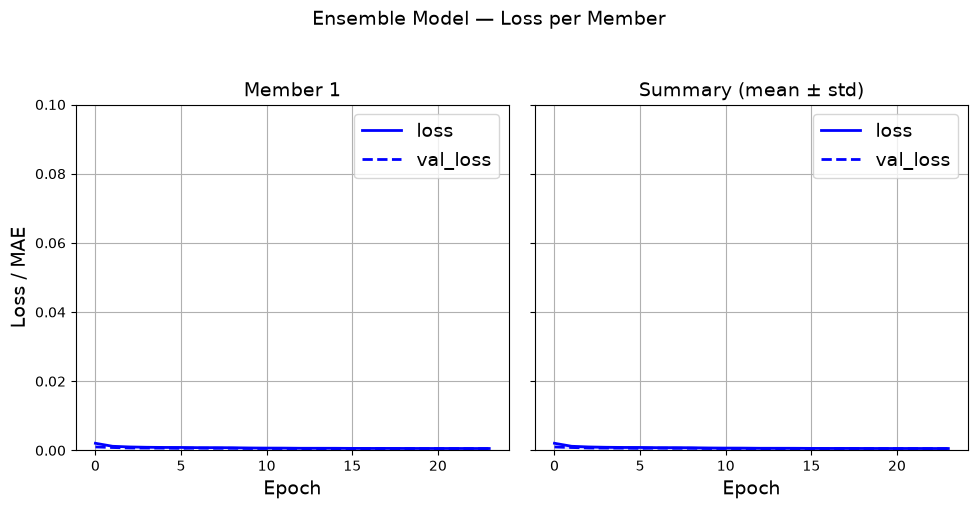

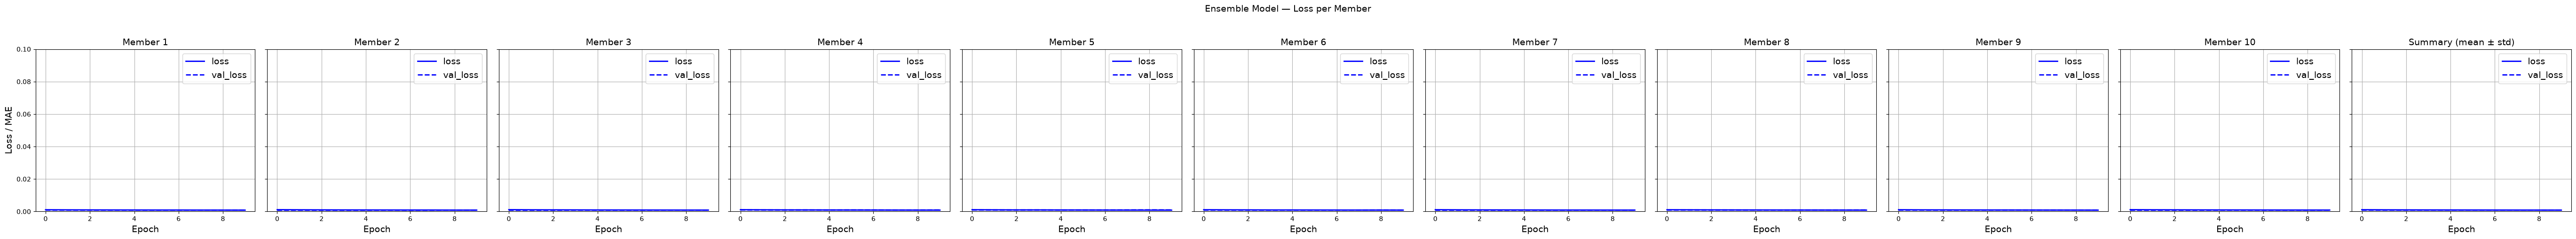

saved outputs/znn_pretrained_popcosmos_noisy_kfold_frombase/pz_challenge_taskset_2_cardinal_pz_model_1yr.pkl

========== task set 2: cardinal_10yr ==========

=== Base model, on all objects with the photometry as given ===
Epoch 1/100


I0000 00:00:1793228215.163365  270152 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_157469__.37


250/250 - 5s - 21ms/step - loss: 0.0013 - val_loss: 3.0330e-04 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 5.8288e-04 - val_loss: 3.1188e-04 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 4.7340e-04 - val_loss: 3.4618e-04 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 4.7640e-04 - val_loss: 2.1244e-04 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 3.9611e-04 - val_loss: 1.8122e-04 - learning_rate: 5.0000e-04
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 3.7561e-04 - val_loss: 1.8519e-04 - learning_rate: 5.0000e-04
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 3.7548e-04 - val_loss: 1.5787e-04 - learning_rate: 5.0000e-04
Epoch 8/100

Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
250/250 - 1s - 3ms/step - loss: 3.6882e-04 - val_loss: 1.5742e-04 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 3m

I0000 00:00:1793228238.800022  270150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_185110__.38
I0000 00:00:1793228241.191524  270150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_185110__.38


282/282 - 7s - 25ms/step - loss: 4.2941e-04 - val_loss: 2.5206e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 4.0646e-04 - val_loss: 2.6860e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 4.1047e-04 - val_loss: 2.5419e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 4.0473e-04 - val_loss: 2.4924e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 3.9658e-04 - val_loss: 2.4716e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 3.9144e-04 - val_loss: 2.8264e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 3.8074e-04 - val_loss: 2.5705e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 3.9079e-04 - val_loss: 2.4737e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 3.9079e-04 - val_loss: 2.3139e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 3.8549e-04 - val_loss: 2.2305e-04

--- Member 2/10 (its own noise realization) ---
Epoch 1/10


...

282/282 - 7s - 26ms/step - loss: 4.4280e-04 - val_loss: 2.1199e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 4.2925e-04 - val_loss: 2.2660e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 4.3071e-04 - val_loss: 2.2672e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 4.1691e-04 - val_loss: 2.0493e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 4.0686e-04 - val_loss: 2.0378e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 4.0427e-04 - val_loss: 2.1127e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 4.0504e-04 - val_loss: 2.3073e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 4.0151e-04 - val_loss: 2.0434e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 4.0015e-04 - val_loss: 2.2056e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 3.9567e-04 - val_loss: 1.9488e-04

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793228354.641783  270150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_286686__.38
I0000 00:00:1793228357.006605  270150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_286686__.38


282/282 - 7s - 25ms/step - loss: 4.5668e-04 - val_loss: 1.8605e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 4.4122e-04 - val_loss: 2.0919e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 4.3047e-04 - val_loss: 1.8628e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 4.2378e-04 - val_loss: 1.8962e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 4.0035e-04 - val_loss: 1.9813e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 4.0178e-04 - val_loss: 1.9981e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 4.0196e-04 - val_loss: 1.7199e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 3.9697e-04 - val_loss: 1.9145e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 4.0088e-04 - val_loss: 1.8462e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 3.9946e-04 - val_loss: 1.7329e-04

--- Member 10/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793228369.242596  270152 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_299383__.38
I0000 00:00:1793228371.592078  270152 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_299383__.38


282/282 - 7s - 26ms/step - loss: 4.3669e-04 - val_loss: 1.8074e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 4.0709e-04 - val_loss: 1.8568e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 4.0835e-04 - val_loss: 1.6882e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 3.9343e-04 - val_loss: 1.7052e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 3.8942e-04 - val_loss: 1.6111e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 3.8056e-04 - val_loss: 1.8748e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 3.8545e-04 - val_loss: 1.6329e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 3.7661e-04 - val_loss: 1.7500e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 3.7556e-04 - val_loss: 1.7182e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 3.7523e-04 - val_loss: 1.9648e-04


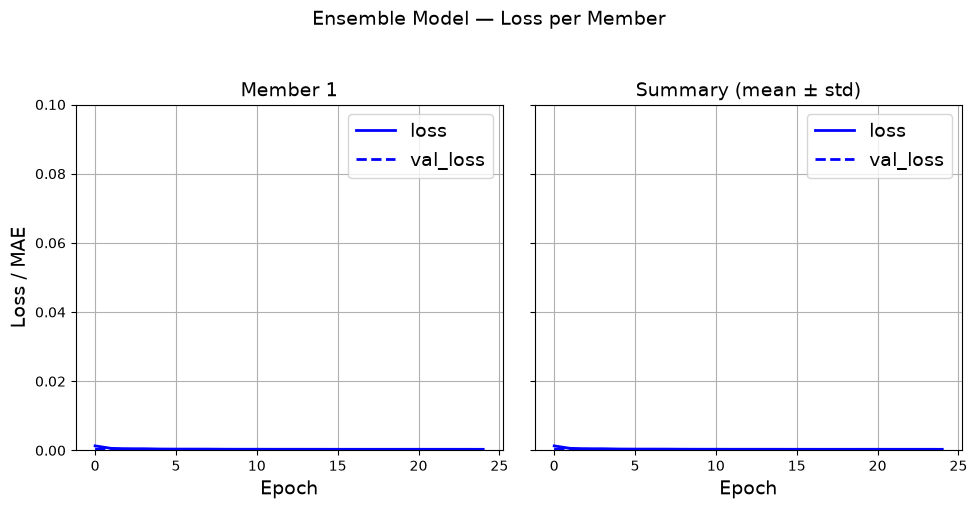

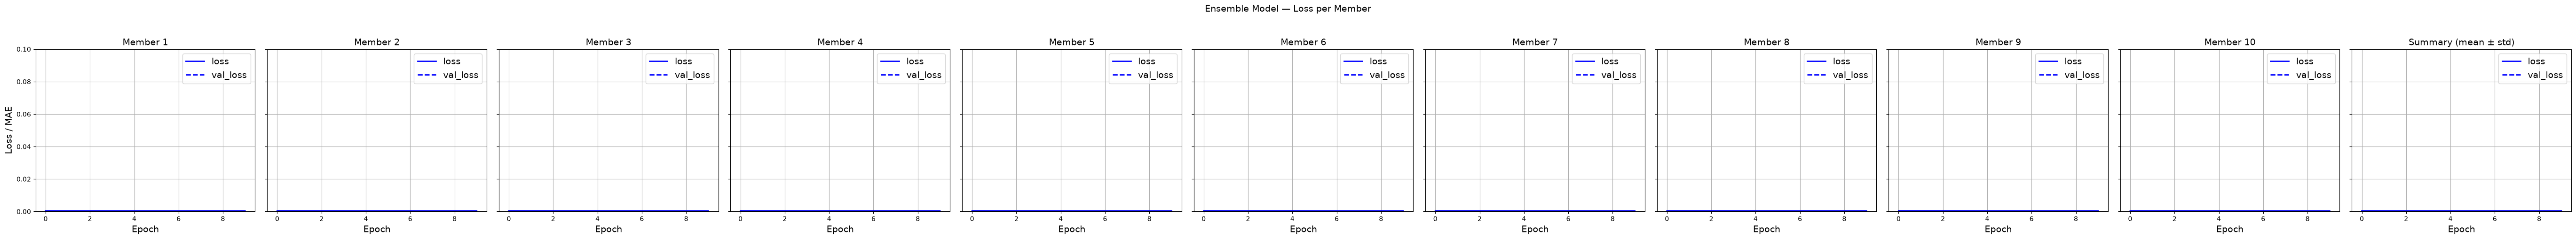

saved outputs/znn_pretrained_popcosmos_noisy_kfold_frombase/pz_challenge_taskset_2_cardinal_pz_model_10yr.pkl

========== task set 2: flagship_1yr ==========

=== Base model, on all objects with the photometry as given ===
Epoch 1/100


I0000 00:00:1793228394.399355  270149 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_312772__.37


250/250 - 5s - 21ms/step - loss: 0.0020 - val_loss: 8.1256e-04 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0012 - val_loss: 7.2360e-04 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0011 - val_loss: 7.5998e-04 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0010 - val_loss: 7.3525e-04 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 9.3002e-04 - val_loss: 5.6735e-04 - learning_rate: 5.0000e-04
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 9.1185e-04 - val_loss: 5.4622e-04 - learning_rate: 5.0000e-04
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 8.8005e-04 - val_loss: 5.3382e-04 - learning_rate: 5.0000e-04
Epoch 8/100

Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
250/250 - 1s - 3ms/step - loss: 8.7529e-04 - val_loss: 5.5458e-04 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 3ms/step - los

I0000 00:00:1793228413.104144  270149 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_333552__.38
I0000 00:00:1793228415.368582  270151 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_333552__.38


282/282 - 7s - 26ms/step - loss: 0.0013 - val_loss: 0.0011
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0013 - val_loss: 0.0011
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0011 - val_loss: 0.0011

--- Member 2/10 (its own noise realization) ---
Epoch 1/10


...

282/282 - 7s - 25ms/step - loss: 0.0014 - val_loss: 0.0010
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0013 - val_loss: 9.1664e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0013 - val_loss: 9.2958e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 9.3883e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 9.7544e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 9.4881e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 9.6269e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 9.6863e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0011 - val_loss: 9.8622e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0011 - val_loss: 0.0010

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793228528.868347  270151 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_435128__.38
I0000 00:00:1793228531.140776  270149 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_435128__.38


282/282 - 7s - 24ms/step - loss: 0.0014 - val_loss: 8.7880e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0013 - val_loss: 8.4114e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0013 - val_loss: 8.6387e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0013 - val_loss: 8.6307e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.2102e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.4605e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.3844e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.1631e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.0404e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.5095e-04

--- Member 10/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793228543.131825  270151 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_447825__.38
I0000 00:00:1793228545.404636  270150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_447825__.38


282/282 - 7s - 24ms/step - loss: 0.0013 - val_loss: 9.4792e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 0.0013 - val_loss: 8.9959e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 0.0013 - val_loss: 9.0395e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 9.0203e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 9.0136e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.7383e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 9.1647e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.8020e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 8.8108e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 0.0012 - val_loss: 9.2282e-04


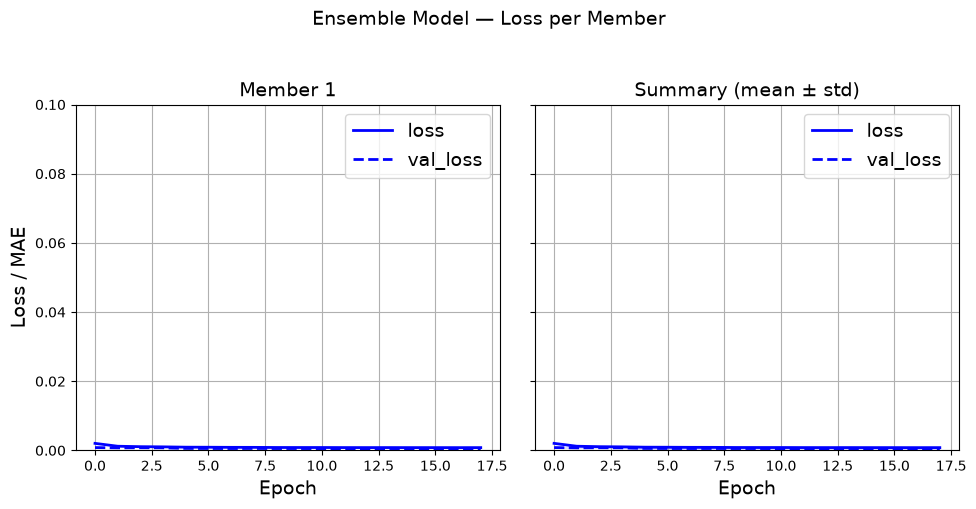

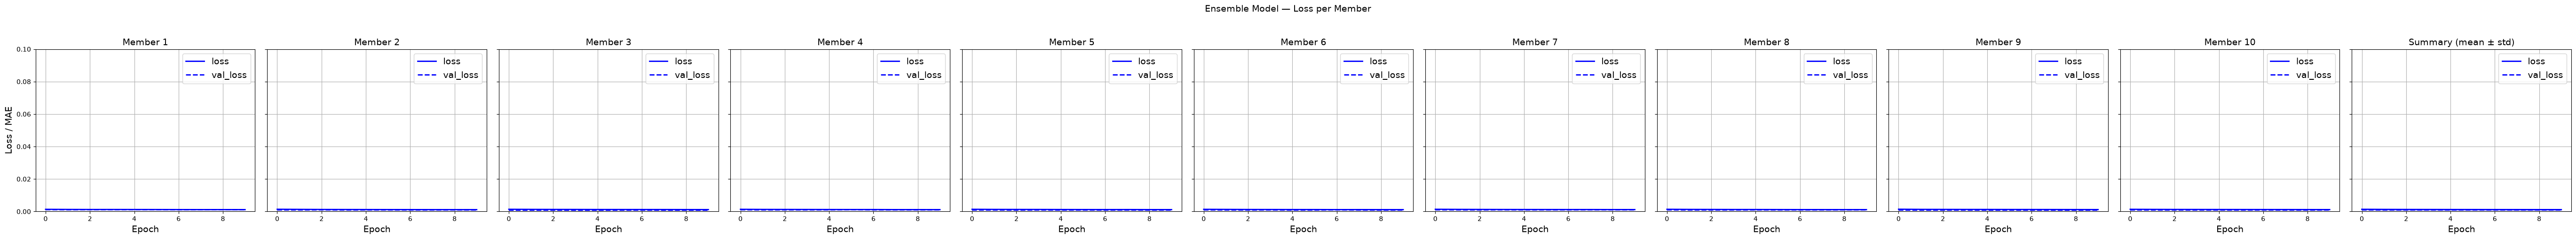

saved outputs/znn_pretrained_popcosmos_noisy_kfold_frombase/pz_challenge_taskset_2_flagship_pz_model_1yr.pkl

========== task set 2: flagship_10yr ==========

=== Base model, on all objects with the photometry as given ===
Epoch 1/100


I0000 00:00:1793228564.834235  270151 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_461214__.37


250/250 - 5s - 21ms/step - loss: 0.0012 - val_loss: 2.1253e-04 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 6.4051e-04 - val_loss: 2.2718e-04 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 5.7996e-04 - val_loss: 1.6120e-04 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 5.6274e-04 - val_loss: 1.5206e-04 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 5.3302e-04 - val_loss: 1.5349e-04 - learning_rate: 5.0000e-04
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 5.3152e-04 - val_loss: 1.2328e-04 - learning_rate: 5.0000e-04
Epoch 7/100

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
250/250 - 1s - 3ms/step - loss: 5.3793e-04 - val_loss: 1.1803e-04 - learning_rate: 5.0000e-04
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 5.2440e-04 - val_loss: 1.3125e-04 - learning_rate: 2.5000e-04
Epoch 9/100
250/250 - 1s - 3m

I0000 00:00:1793228581.075880  270152 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_479009__.38
I0000 00:00:1793228583.442693  270150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_479009__.38


282/282 - 7s - 25ms/step - loss: 5.8458e-04 - val_loss: 1.7586e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 5.7893e-04 - val_loss: 1.8288e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 5.7894e-04 - val_loss: 1.7830e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 5.7685e-04 - val_loss: 2.0218e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 5.7283e-04 - val_loss: 1.8589e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 5.7356e-04 - val_loss: 1.7082e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 5.7031e-04 - val_loss: 1.7295e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 5.6266e-04 - val_loss: 1.6843e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 5.5896e-04 - val_loss: 1.6896e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 5.7427e-04 - val_loss: 1.8308e-04

--- Member 2/10 (its own noise realization) ---
Epoch 1/10


...

282/282 - 7s - 25ms/step - loss: 5.9414e-04 - val_loss: 1.9515e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 5.7761e-04 - val_loss: 1.7347e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 5.6905e-04 - val_loss: 1.8854e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 5.7662e-04 - val_loss: 1.7582e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 5.6876e-04 - val_loss: 1.7553e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 5.7613e-04 - val_loss: 1.7254e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 5.6306e-04 - val_loss: 1.7550e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 5.6822e-04 - val_loss: 1.7420e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 5.6520e-04 - val_loss: 1.7174e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 5.6402e-04 - val_loss: 1.7636e-04

--- Member 9/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793228697.823564  270150 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_580585__.38
I0000 00:00:1793228700.099999  270149 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_580585__.38


282/282 - 7s - 25ms/step - loss: 5.8507e-04 - val_loss: 1.7549e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 5.8705e-04 - val_loss: 1.8782e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 5.8335e-04 - val_loss: 1.8555e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 5.7062e-04 - val_loss: 1.9353e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 5.6805e-04 - val_loss: 1.5724e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 5.7838e-04 - val_loss: 1.6283e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 5.7350e-04 - val_loss: 1.5236e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 5.6768e-04 - val_loss: 1.8187e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 5.6879e-04 - val_loss: 1.7470e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 5.6955e-04 - val_loss: 1.5508e-04

--- Member 10/10 (its own noise realization) ---
Epoch 1/10


I0000 00:00:1793228712.486980  270153 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_593282__.38
I0000 00:00:1793228714.853361  270149 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_593282__.38


282/282 - 7s - 25ms/step - loss: 5.9059e-04 - val_loss: 1.7045e-04
Epoch 2/10
282/282 - 1s - 3ms/step - loss: 5.7431e-04 - val_loss: 1.7169e-04
Epoch 3/10
282/282 - 1s - 3ms/step - loss: 5.7865e-04 - val_loss: 1.8298e-04
Epoch 4/10
282/282 - 1s - 3ms/step - loss: 5.6420e-04 - val_loss: 1.7916e-04
Epoch 5/10
282/282 - 1s - 3ms/step - loss: 5.7022e-04 - val_loss: 1.6692e-04
Epoch 6/10
282/282 - 1s - 3ms/step - loss: 5.6710e-04 - val_loss: 1.7115e-04
Epoch 7/10
282/282 - 1s - 3ms/step - loss: 5.6065e-04 - val_loss: 1.8008e-04
Epoch 8/10
282/282 - 1s - 3ms/step - loss: 5.6487e-04 - val_loss: 1.5562e-04
Epoch 9/10
282/282 - 1s - 3ms/step - loss: 5.7367e-04 - val_loss: 1.7944e-04
Epoch 10/10
282/282 - 1s - 3ms/step - loss: 5.5743e-04 - val_loss: 1.6854e-04


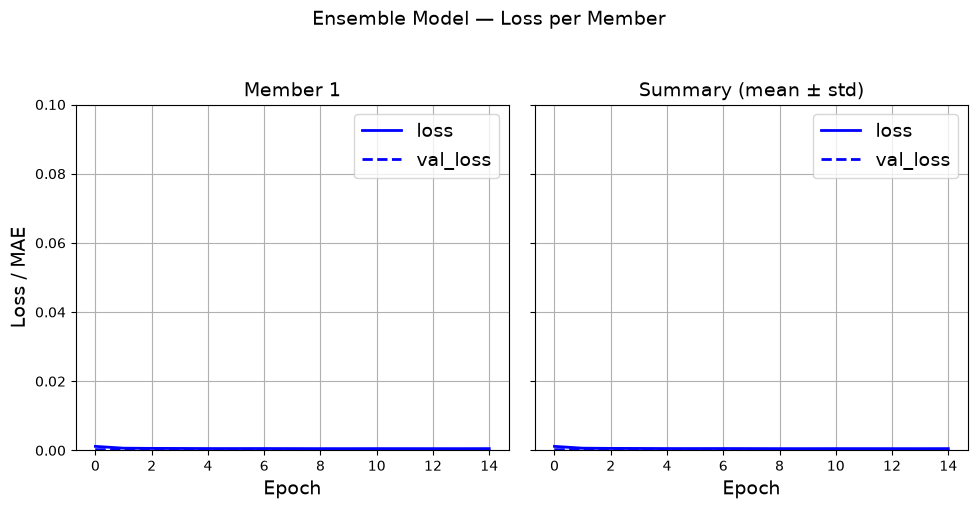

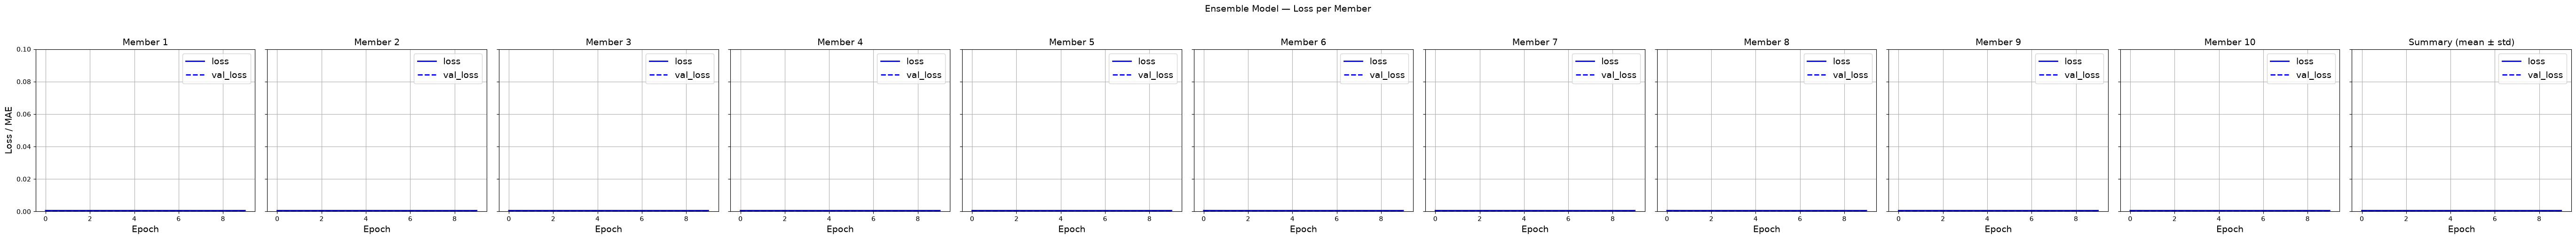

saved outputs/znn_pretrained_popcosmos_noisy_kfold_frombase/pz_challenge_taskset_2_flagship_pz_model_10yr.pkl


In [4]:
for SIM in SIMS:
    for SCENARIO in SCENARIOS:
        config = f"{SIM}_{SCENARIO}"
        print(f"\n========== task set {TASKSET}: {config} ==========")

        train_file = os.path.join(DATA_DIR, f"pz_challenge_taskset_{TASKSET}_{SIM}_training_{SCENARIO}.hdf5")
        train = znn.read_catalog(train_file)
        z_ref, _ = reference_redshifts(train)

        rng = np.random.default_rng(NOISE_SEED)
        # the held-out split is not used here, only kept out of training (pz_challenge_results.ipynb scores on it)
        idx_fit, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
        trained_models, histories, base_history = znn.train_from_catalog(
            znn.build_model, train.iloc[idx_fit], z_ref[idx_fit], BANDS, REF_BAND, FEATURE_CONFIG, errors=ERRORS, rng=rng,
            N_MEMBERS=N_MEMBERS, from_base=FROM_BASE, EPOCHS=EPOCHS, FINETUNE_EPOCHS=FINETUNE_EPOCHS,
            FINETUNE_LR=FINETUNE_LR, random_state=SEED, pretraining=PRETRAINING,
        )
        if base_history is not None:
            znn.plot_ensemble_losses([base_history], ylim=(0, 0.1))
        znn.plot_ensemble_losses(histories, ylim=(0, 0.1))

        # subtask 2 submission file: the trained ensemble
        model_file = os.path.join(OUT_DIR, f"pz_challenge_taskset_{TASKSET}_{SIM}_pz_model_{SCENARIO}.pkl")
        znn.save_ensemble_file(model_file, trained_models, BANDS, REF_BAND, FEATURE_CONFIG)
        print("saved", model_file)